# Projeto 2 — Task 2: modelos estatísticos de previsão

**Mineração de Dados 2026/27 · Previsão *day-ahead* da procura de carregamento de veículos elétricos**

**Objetivo desta Task.** Selecionar, configurar e avaliar modelos estatísticos de séries temporais para prever o número de sessões que começam em cada uma das próximas 24 horas, ao nível da rede e de cada distrito, e compará-los com as *baselines* da Task 1 **usando exatamente o protocolo fixado na Task 1**.

**Estrutura**

0. Configuração e dados (artefactos da Task 1)
1. Motor de avaliação comum (interface dos modelos, métricas, verificação com as *baselines*)
2. Decisões transversais: janela de treino e transformação
3. Suavização exponencial (ETS, ETS semanal e MSTL + ETS)
4. Identificação ARIMA
5. SARIMA e MSTL + ARIMA
6. SARIMAX com variáveis exógenas
7. Comparação global
8. Discussão transversal
9. Síntese

**Regra de rigor.** Tudo o que se decide nesta Task usa **apenas os 4 *folds* de validação** (2020-Q4 a 2021-Q3). O teste final (2021-Q4) não é usado: o motor de avaliação recusa qualquer bloco que o toque.

## 0. Configuração e dados

O notebook lê os três ficheiros exportados pela Task 1 (`hourly_series_task1.csv`, `daily_weather_task1.csv` e `protocol_task1.json`). As partições, a data de início da escala do MASE e a *baseline* de referência vêm do JSON do protocolo, e não são reescritas aqui, para garantir que a Task 2 usa exatamente o mesmo enquadramento.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import stats
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Artefactos da Task 1: procurados na pasta do notebook e na pasta acima.
def find_file(name):
    for p in [Path(name), Path("..") / name, Path("../Parte2") / name]:
        if p.exists():
            return p
    raise FileNotFoundError(f"{name} não encontrado: corra primeiro o task1.ipynb (secção 6) para o gerar.")

SERIES_PATH, WEATHER_PATH, PROTOCOL_PATH = (find_file(n) for n in
    ["hourly_series_task1.csv", "daily_weather_task1.csv", "protocol_task1.json"])
OUT_DIR = Path("task2_outputs")
OUT_DIR.mkdir(exist_ok=True)

N_JOBS = -1  # processos em paralelo no motor de avaliação (-1 = todos os núcleos)

series = pd.read_csv(SERIES_PATH, index_col="hour", parse_dates=True)
weather_daily = pd.read_csv(WEATHER_PATH, parse_dates=["date", "known_at"])
PROTOCOL = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))

LEVELS = PROTOCOL["series"]["levels"]
DISTRICTS = [lv for lv in LEVELS if lv != "Network"]
SERIES_START = pd.Timestamp(PROTOCOL["series"]["start"])
SERIES_END = pd.Timestamp(PROTOCOL["series"]["end"])
FOLDS = [{"name": f["name"], "train": tuple(f["train"]), "val": tuple(f["validation"])} for f in PROTOCOL["splits"]["folds"]]
TEST = tuple(PROTOCOL["splits"]["test"])
TEST_START = pd.Timestamp(TEST[0])
MASE_SCALE_FROM = pd.Timestamp(PROTOCOL["metrics"]["mase_scale_from"])
M_SEASON = PROTOCOL["metrics"]["mase_seasonal_period"]
REFERENCE = PROTOCOL["reference_baseline"]
HOLIDAY_DAYS = pd.DatetimeIndex([d for h in PROTOCOL["holidays"] for d in pd.date_range(h["from"], h["to"], freq="D")])

DAYS = pd.date_range(SERIES_START.normalize(), SERIES_END.normalize(), freq="D")
day_idx = lambda d: int((pd.Timestamp(d) - DAYS[0]).days)
hidx = lambda t: int((pd.Timestamp(t) - SERIES_START) / pd.Timedelta(hours=1))
Y = {lv: series[lv].to_numpy().astype(float) for lv in LEVELS}

assert len(series) == PROTOCOL["series"]["n_hours"] == len(DAYS) * 24
assert series.index[0] == SERIES_START and series.index.is_monotonic_increasing
assert (series[DISTRICTS].sum(axis=1) == series["Network"]).all()
assert M_SEASON == 24 and set(REFERENCE.values()) == {"MediaHora-7d"}

COLORS = {"Network": "#1F77B4", "Nanhu": "#2CA02C", "Tongxiang": "#FF7F0E", "Xiuzhou": "#9467BD"}
display(pd.DataFrame(
    [{"bloco": f["name"], "treino": f"{f['train'][0]} a {f['train'][1]}", "validação": f"{f['val'][0]} a {f['val'][1]}",
      "origens": day_idx(f["val"][1]) - day_idx(f["val"][0]) + 1} for f in FOLDS]
    + [{"bloco": "Teste (não usado)", "treino": "—", "validação": f"{TEST[0]} a {TEST[1]}", "origens": day_idx(TEST[1]) - day_idx(TEST[0]) + 1}]
).set_index("bloco"))
print("Escala do MASE desde:", MASE_SCALE_FROM.date(), "| período sazonal m =", M_SEASON, "| referência:", REFERENCE["Network"])

,treino,validação,origens
bloco,,,
F1,2020-01-01 a 2020-09-30,2020-10-01 a 2020-12-31,92
F2,2020-01-01 a 2020-12-31,2021-01-01 a 2021-03-31,90
F3,2020-01-01 a 2021-03-31,2021-04-01 a 2021-06-30,91
F4,2020-01-01 a 2021-06-30,2021-07-01 a 2021-09-30,92
Teste (não usado),—,2021-10-01 a 2021-12-31,92


Escala do MASE desde: 2020-04-01 | período sazonal m = 24 | referência: MediaHora-7d


**Protocolo herdado da Task 1 (resumo).**

| Elemento | Decisão |
|---|---|
| Emissão | diária às 00:00; horizontes $h=1,\dots,24$ = as 24 horas do dia $D$ |
| Informação | só a procura observada até $T_0-1\,$h (e calendário); nada do dia $D$ |
| Estratégia (estatísticos) | iterada: parâmetros estimados **uma vez por *fold***; em cada origem o estado é atualizado com os dados até $T_0$, **sem reestimar** |
| Validação | 4 *folds* trimestrais de janela expansiva; teste 2021-Q4 protegido |
| Métricas | MAE, RMSE, MASE ($m=24$, escala desde 2020-04-01), acerto e erro do pico, custo |
| Referência | MédiaHora-7d em todos os níveis |
| Regra de seleção | MASE médio menor, melhor em ≥ 3 de 4 *folds* e IC 95% da diferença pareada de MASE diário a excluir zero |

## 1. Motor de avaliação comum

Todos os modelos desta Task (e das seguintes) passam pelo **mesmo motor**, para serem comparados nas mesmas origens, com as mesmas métricas e sem fugas de informação.

### 1.1 Interface dos modelos

Cada modelo é uma classe com dois métodos:

- `fit(y_train)`: recebe a série desde 2020-01-01 até ao último instante do treino do *fold* e estima os parâmetros. É chamado **uma vez por *fold* e por nível**.
- `predict(y_hist)`: recebe a série **já cortada** em $T_0$ (termina na hora 23:00 do dia anterior) e devolve as 24 previsões do dia $D$. Pode atualizar o estado do modelo com esses dados, mas não reestima parâmetros.

Como o motor só entrega ao `predict` o histórico cortado, **um modelo não consegue ver o futuro por construção** (a mesma garantia das *baselines* da Task 1). O motor também recusa qualquer bloco que entre no teste.

As *baselines* da Task 1 são reescritas nesta interface (sem `fit`), o que permite verificar o motor: tem de reproduzir os números da Task 1.

In [2]:
class Forecaster:
    # Classe base: as subclasses implementam fit e predict.
    name = "base"

    def fit(self, y_train):
        return self

    def predict(self, y_hist):
        raise NotImplementedError

    def info(self):
        # Informação extra a guardar por (nível, fold): parâmetros, AICc, etc.
        return {}


class Naive(Forecaster):
    def predict(self, y_hist): return np.full(24, y_hist[-1])

class SNaive24(Forecaster):
    def predict(self, y_hist): return y_hist[-24:].copy()

class SNaive168(Forecaster):
    def predict(self, y_hist): return y_hist[-168:-144].copy()

class MediaHora7d(Forecaster):
    def predict(self, y_hist): return y_hist[-168:].reshape(7, 24).mean(axis=0)

class MediaHora4sem(Forecaster):
    def predict(self, y_hist): return np.mean([y_hist[len(y_hist) - 168 * k: len(y_hist) - 168 * k + 24] for k in range(1, 5)], axis=0)

BASELINES = {"Naive": Naive, "SNaive-24": SNaive24, "SNaive-168": SNaive168,
             "MediaHora-7d": MediaHora7d, "MediaHora-4sem": MediaHora4sem}

In [3]:
def _run_one(make_model, level, fold):
    # Um nível × um fold: ajusta uma vez e prevê todas as origens do bloco de validação.
    y = Y[level]
    d0, d1 = day_idx(fold["val"][0]), day_idx(fold["val"][1])
    assert DAYS[d1] < TEST_START, "o motor não avalia blocos que entrem no teste"
    n_train = d0 * 24
    assert pd.Timestamp(fold["train"][1]) + pd.Timedelta(hours=23) == series.index[n_train - 1]
    model = make_model()
    t0 = time.perf_counter()
    model.fit(y[:n_train].copy())
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    fc = []
    for d in range(d0, d1 + 1):
        y_hist = y[:d * 24].copy()              # histórico cortado em T0 = 00:00 do dia d
        f = np.asarray(model.predict(y_hist), dtype=float)
        assert f.shape == (24,) and np.isfinite(f).all()
        fc.append(np.clip(f, 0, None))          # procura nunca negativa
    pred_s = (time.perf_counter() - t0) / (d1 - d0 + 1)
    return level, fold["name"], np.vstack(fc), fit_s, pred_s, model.info()


RESULTS = {}

def run_model(name, make_model, levels=LEVELS, folds=FOLDS, n_jobs=None, verbose=True):
    # Avalia um modelo em todos os níveis e folds, calcula as métricas e guarda em RESULTS[name].
    t0 = time.perf_counter()
    jobs = [(lv, f) for lv in levels for f in folds]
    out = Parallel(n_jobs=N_JOBS if n_jobs is None else n_jobs)(delayed(_run_one)(make_model, lv, f) for lv, f in jobs)
    RESULTS[name] = compute_metrics(name, out)
    if verbose:
        print(f"{name}: {len(jobs)} ajustes (nível × fold) em {time.perf_counter() - t0:.1f} s")
    return RESULTS[name]

### 1.2 Métricas e agregação

As métricas seguem a secção 5.2 da Task 1:

- **MAE** (erro absoluto médio, em sessões/hora) e **RMSE** (raiz do erro quadrático médio; castiga mais os erros grandes, como falhar um pico).
- **MASE** = MAE do modelo ÷ MAE *in-sample* do *seasonal naïve* de 24 h no treino de cada *fold* e nível (desde 2020-04-01). Abaixo de 1, o modelo erra menos do que "repetir o dia anterior" erraria no treino; permite comparar níveis com volumes muito diferentes.
- **Pico:** acerto da hora de pico do dia (±1 h) e erro absoluto do valor do pico.
- **Custo:** tempo de ajuste por *fold* e tempo de previsão por origem.

Agregação: MAE e RMSE globais sobre todas as origens de validação (o RMSE global é a raiz da média de todos os erros quadráticos); o MASE global é a média dos MASE dos *folds*, porque cada *fold* tem a sua escala. O MASE diário é guardado para a comparação pareada com a referência.

In [4]:
def mase_scale(level, fold):
    s0, n_train = hidx(MASE_SCALE_FROM), day_idx(fold["val"][0]) * 24
    y = Y[level]
    return np.abs(y[s0 + M_SEASON:n_train] - y[s0:n_train - M_SEASON]).mean()

SCALES = {(lv, f["name"]): mase_scale(lv, f) for lv in LEVELS for f in FOLDS}
FOLD_BY_NAME = {f["name"]: f for f in FOLDS}


def compute_metrics(name, out):
    by_h, by_fold, by_day, preds, info = [], [], [], [], []
    for level, fname, fc, fit_s, pred_s, inf in out:
        f = FOLD_BY_NAME[fname]
        d0, d1 = day_idx(f["val"][0]), day_idx(f["val"][1])
        act = Y[level][d0 * 24:(d1 + 1) * 24].reshape(-1, 24)
        err, scale = act - fc, SCALES[(level, fname)]
        mae_h, mse_h = np.abs(err).mean(axis=0), (err ** 2).mean(axis=0)
        for h in range(24):
            by_h.append((fname, level, name, h + 1, mae_h[h], np.sqrt(mse_h[h]), mae_h[h] / scale))
        for i, v in enumerate(np.abs(err).mean(axis=1) / scale):
            by_day.append((fname, level, name, DAYS[d0 + i], v))
        by_fold.append({
            "fold": fname, "level": level, "model": name,
            "MAE": mae_h.mean(), "RMSE": np.sqrt(mse_h.mean()), "MASE": mae_h.mean() / scale,
            "peak_hit": (np.abs(fc.argmax(1) - act.argmax(1)) <= 1).mean(),
            "peak_mae": np.abs(fc.max(1) - act.max(1)).mean(),
            "fit_s": fit_s, "ms_per_origin": pred_s * 1000, "n_origins": len(fc),
        })
        preds.append(pd.DataFrame({
            "model": name, "level": level, "fold": fname,
            "origin": np.repeat(DAYS[d0:d1 + 1], 24),
            "timestamp": series.index[d0 * 24:(d1 + 1) * 24],
            "h": np.tile(np.arange(1, 25), d1 - d0 + 1),
            "y_true": act.ravel(), "y_pred": fc.ravel(),
        }))
        info.append({"level": level, "fold": fname, **inf})
    return {
        "res_h": pd.DataFrame(by_h, columns=["fold", "level", "model", "horizon", "MAE", "RMSE", "MASE"]),
        "res_f": pd.DataFrame(by_fold),
        "res_d": pd.DataFrame(by_day, columns=["fold", "level", "model", "day", "MASE_dia"]),
        "preds": pd.concat(preds, ignore_index=True),
        "info": pd.DataFrame(info),
    }


def paired_ci(d, block=7, n_boot=2000, seed=0):
    # IC 95% da média de d por bootstrap de blocos de 7 dias (igual à Task 1).
    rng = np.random.default_rng(seed)
    n = len(d)
    k = -(-n // block)
    starts = rng.integers(0, n - block + 1, size=(n_boot, k))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    return np.percentile(d[idx].mean(axis=1), [2.5, 97.5])


def summarize(names, levels=LEVELS, with_rule=True):
    # Tabela por nível e modelo: métricas globais, estabilidade entre folds e regra de seleção face à referência.
    rows = []
    for name in names:
        rf, rd = RESULTS[name]["res_f"], RESULTS[name]["res_d"]
        for lv in levels:
            sub = rf[rf["level"] == lv]
            n = sub["n_origins"]
            row = {
                "level": lv, "model": name,
                "MAE": (sub["MAE"] * n).sum() / n.sum(),
                "RMSE": np.sqrt((sub["RMSE"] ** 2 * n).sum() / n.sum()),
                "MASE": sub["MASE"].mean(), "MASE_dp": sub["MASE"].std(), "MASE_pior": sub["MASE"].max(),
                "pico_acerto": sub["peak_hit"].mean(), "pico_MAE": sub["peak_mae"].mean(),
                "ajuste_s": sub["fit_s"].mean(), "ms_origem": sub["ms_per_origin"].mean(),
            }
            ref = REFERENCE[lv]
            if with_rule and name != ref and ref in RESULTS:
                rref = RESULTS[ref]
                ref_f = rref["res_f"][rref["res_f"]["level"] == lv].set_index("fold")["MASE"]
                wins = int((sub.set_index("fold")["MASE"] < ref_f).sum())
                a = rd[rd["level"] == lv].set_index("day")["MASE_dia"].sort_index()
                b = rref["res_d"][rref["res_d"]["level"] == lv].set_index("day")["MASE_dia"].sort_index()
                diff = (a - b).to_numpy()
                lo, hi = paired_ci(diff)
                row.update({"Δ_MASE_vs_ref": diff.mean(), "IC_inf": lo, "IC_sup": hi, "folds_ganhos": wins,
                            "melhor_que_ref": "sim" if (diff.mean() < 0 and wins >= 3 and hi < 0) else "não"})
            rows.append(row)
    return pd.DataFrame(rows)


def show_summary(names, levels=LEVELS, cols=None, sort="MASE"):
    tbl = summarize(names, levels)
    cols = cols or [c for c in tbl.columns if c not in ("level", "model")]
    for lv in levels:
        print(f"--- {lv} ---")
        display(tbl[tbl["level"] == lv].set_index("model")[cols].sort_values(sort).round(3))
    return tbl


def fold_table(names, metric="MASE"):
    rf = pd.concat([RESULTS[n]["res_f"] for n in names])
    return rf.pivot_table(index=["level", "model"], columns="fold", values=metric).reindex(LEVELS, level=0)


def plot_by_horizon(names, metric="MASE", title=None, styles=None):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharex=True)
    for ax, lv in zip(axes, LEVELS):
        for n in names:
            rh = RESULTS[n]["res_h"]
            v = rh[rh["level"] == lv].groupby("horizon")[metric].mean()
            ax.plot(v.index, v.values, label=n, **(styles or {}).get(n, {}))
        ax.set(title=lv, xlabel="horizonte h (= hora do dia + 1)", ylabel=metric if lv == "Network" else "")
        ax.set_xticks([1, 6, 12, 18, 24])
    axes[0].legend(fontsize=7)
    if title:
        fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

### 1.3 Verificação do motor: reproduzir as *baselines* da Task 1

Se o motor estiver correto, as cinco *baselines* têm de dar **exatamente** os valores da secção 5.3 da Task 1 (por exemplo, MASE da MédiaHora-7d: Rede 0,825, Nanhu 0,639, Tongxiang 0,834, Xiuzhou 0,890).

In [5]:
for name, cls in BASELINES.items():
    run_model(name, cls, verbose=False)

TASK1_REF_MASE = {"Network": 0.825, "Nanhu": 0.639, "Tongxiang": 0.834, "Xiuzhou": 0.890}
base_tbl = summarize(list(BASELINES), with_rule=False)
check = base_tbl[base_tbl["model"] == "MediaHora-7d"].set_index("level")["MASE"]
for lv, v in TASK1_REF_MASE.items():
    assert abs(check[lv] - v) < 5e-4, (lv, check[lv], v)
print("Motor verificado: a MédiaHora-7d reproduz os MASE da Task 1 em todos os níveis.")
display(base_tbl.pivot(index="model", columns="level", values="MASE")[LEVELS].sort_values("Network").round(3))

Motor verificado: a MédiaHora-7d reproduz os MASE da Task 1 em todos os níveis.


level,Network,Nanhu,Tongxiang,Xiuzhou
model,,,,
MediaHora-7d,0.825,0.639,0.834,0.890
MediaHora-4sem,0.916,0.694,0.925,0.940
SNaive-24,1.022,0.814,1.032,1.130
SNaive-168,1.095,0.824,1.110,1.159
Naive,2.149,1.115,1.857,1.682


**Leitura.** O motor reproduz os valores da Task 1 nos quatro níveis (as asserções passam), por isso as previsões, a escala do MASE e a agregação estão alinhadas com o protocolo. A partir daqui, qualquer modelo avaliado neste motor é diretamente comparável com as *baselines*, e **a referência a bater continua a ser a MédiaHora-7d**.

## 2. Decisões transversais: janela de treino e transformação

A Task 1 deixou duas decisões em aberto, que afetam todos os modelos estatísticos desta Task (ETS, ARIMA e SARIMAX). Tomam-se aqui, **uma vez**, com um modelo simples e barato, e ficam fixas para as secções seguintes:

1. **Transformação da série:** modelar a procura tal como está ou depois de `log1p`?
2. **Janela de treino:** a partir de quando se estimam os parâmetros, dado o colapso de janeiro-março de 2020?

O modelo usado como instrumento é o **ETS(A,N,A)** (Holt-Winters aditivo sem tendência, sazonalidade de 24 h; ver secção 3), o mais simples que capta o ciclo diário. A decisão é tomada com o mesmo critério do protocolo: MASE nos 4 *folds* de validação.

### 2.1 Porque considerar uma transformação?

Nas contagens, o erro tende a crescer com o nível da procura (a Task 1 viu-o nos resíduos da MSTL). Um modelo aditivo assume uma variação de tamanho constante, o que não se ajusta a esse comportamento. A transformação `log1p` ($z = \ln(1 + y)$) comprime os valores altos: um mesmo aumento percentual passa a ter sempre o mesmo tamanho, e a sazonalidade multiplicativa torna-se aditiva (como no exemplo AirPassengers das aulas). Usa-se $\ln(1+y)$ em vez de $\ln(y)$ porque há horas com zero sessões (20% em Nanhu), onde $\ln(0)$ não existe. A previsão volta à escala original com $y = e^{z} - 1$.

O gráfico verifica a premissa sem usar nenhum modelo: agrupa as horas do desenvolvimento (desde 2020-04-01) pelo nível esperado (a MédiaHora-7d dessa hora) e mostra o tamanho médio da variação face a esse nível, na escala original e na escala `log1p`.

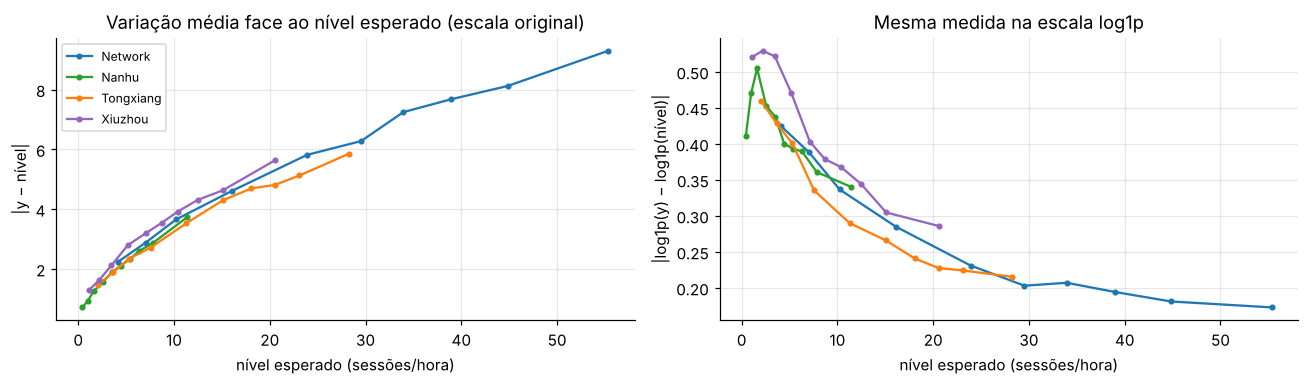

,escala original: decil mais alto ÷ mediano,escala log1p: decil mais alto ÷ mediano
nível,,
Network,1.480,0.850
Nanhu,1.770,0.850
Tongxiang,1.360,0.810
Xiuzhou,1.590,0.760


In [6]:
dev_from, dev_to = hidx(MASE_SCALE_FROM) + 168, hidx(TEST_START)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
het_rows = []
for lv in LEVELS:
    y = Y[lv]
    # nível esperado de cada hora = média da mesma hora nos 7 dias anteriores (só passado)
    lvl = np.array([y[t - 168:t:24].mean() for t in range(dev_from, dev_to)])
    obs = y[dev_from:dev_to]
    bins = pd.qcut(lvl, 10, duplicates="drop")
    raw = pd.Series(np.abs(obs - lvl)).groupby(bins, observed=True).mean()
    log = pd.Series(np.abs(np.log1p(obs) - np.log1p(lvl))).groupby(bins, observed=True).mean()
    centers = pd.Series(lvl).groupby(bins, observed=True).mean()
    ax[0].plot(centers.values, raw.values, marker="o", ms=3, color=COLORS[lv], label=lv)
    ax[1].plot(centers.values, log.values, marker="o", ms=3, color=COLORS[lv], label=lv)
    hi_lo = lambda s: s.iloc[-1] / s.iloc[len(s) // 2]
    het_rows.append({"nível": lv, "escala original: decil mais alto ÷ mediano": hi_lo(raw), "escala log1p: decil mais alto ÷ mediano": hi_lo(log)})
ax[0].set(title="Variação média face ao nível esperado (escala original)", xlabel="nível esperado (sessões/hora)", ylabel="|y − nível|")
ax[1].set(title="Mesma medida na escala log1p", xlabel="nível esperado (sessões/hora)", ylabel="|log1p(y) − log1p(nível)|")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(het_rows).set_index("nível").round(2))

**Leitura.**

- **Escala original (esquerda):** a variação cresce de forma quase linear com o nível esperado. Nas horas mais movimentadas, é 1,4 a 1,8 vezes maior do que nas horas de procura mediana. É a heterocedasticidade que um modelo aditivo não representa: o modelo trataria igualmente um desvio de 5 sessões às 4h (enorme) e às 15h (normal).
- **Escala `log1p` (direita):** a relação inverte-se e fica muito mais plana nas horas com procura. O decil mais alto passa a ter 0,76 a 0,85 vezes a variação do decil mediano. Nas horas de procura muito baixa (noite, Nanhu), o `log1p` exagera ligeiramente a variação, porque com contagens de 0 a 3 sessões qualquer diferença de uma sessão é grande em termos relativos.

**Implicação:** o `log1p` não torna a variância perfeitamente constante, mas aproxima-a muito mais do que a escala original. A escolha final é empírica e faz-se na experiência seguinte.

### 2.2 Experiência: janela de treino × transformação

Combinam-se três janelas com as duas escalas (6 configurações × 4 níveis × 4 *folds*):

| Janela | Treino usado para estimar os parâmetros | Argumento |
|---|---|---|
| **completa** | desde 2020-01-01 (inclui o colapso) | mais dados |
| **regular** | desde 2020-04-01 | exclui um regime que não se repete (COVID-19 e Festival da Primavera de 2020) |
| **deslizante-12sem** | só as 12 semanas anteriores ao *fold* | adapta-se a mudanças de nível, mas com menos dados |

Em todas, os parâmetros são estimados uma vez por *fold* e o estado é atualizado diariamente com os dados até $T_0$. A janela define também onde começa essa atualização (o estado inicial é estimado no início da janela).

In [7]:
TRANSFORMS = {"nenhuma": (lambda y: y, lambda z: z), "log1p": (np.log1p, np.expm1)}
WINDOW_START = {
    "completa": lambda n_train: 0,
    "regular": lambda n_train: hidx("2020-04-01"),
    "deslizante-12sem": lambda n_train: n_train - 12 * 168,
}


class ETSForecaster(Forecaster):
    # ETS com erro aditivo. trend: None/"add"; damped: tendência amortecida; m: período sazonal (24 ou 168); seasonal: "add" ou None.
    def __init__(self, trend=None, damped=False, seasonal="add", m=24, window="regular", transform="log1p", bias_adj=False):
        self.trend, self.damped, self.seasonal, self.m = trend, damped, seasonal, m
        self.window, self.transform, self.bias_adj = window, transform, bias_adj

    def _model(self, z):
        return ETSModel(z, error="add", trend=self.trend, damped_trend=self.damped, seasonal=self.seasonal,
                        seasonal_periods=self.m if self.seasonal else None, initialization_method="heuristic")

    def fit(self, y_train):
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        self.res_ = self._model(fwd(y_train[self.s0:])).fit(disp=False, maxiter=1000)
        self.params = self.res_.params
        self.sigma2 = float(np.var(self.res_.resid))
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        f = self._model(fwd(y_hist[self.s0:])).smooth(self.params).forecast(24)
        if self.transform == "log1p" and self.bias_adj:
            return np.exp(f + self.sigma2 / 2) - 1   # média em vez de mediana na escala original
        return inv(f)

    def info(self):
        names = self.res_.model.param_names
        return {**dict(zip(names, self.params)), "AICc": self.res_.aicc, "inicio_janela": str(series.index[self.s0].date())}


cfg_names = []
for w in WINDOW_START:
    for t in TRANSFORMS:
        nm = f"ETS(A,N,A) | {w} | {t}"
        run_model(nm, lambda w=w, t=t: ETSForecaster(window=w, transform=t))
        cfg_names.append(nm)

ETS(A,N,A) | completa | nenhuma: 16 ajustes (nível × fold) em 8.4 s


ETS(A,N,A) | completa | log1p: 16 ajustes (nível × fold) em 7.4 s


ETS(A,N,A) | regular | nenhuma: 16 ajustes (nível × fold) em 6.4 s


ETS(A,N,A) | regular | log1p: 16 ajustes (nível × fold) em 6.2 s


ETS(A,N,A) | deslizante-12sem | nenhuma: 16 ajustes (nível × fold) em 2.8 s


ETS(A,N,A) | deslizante-12sem | log1p: 16 ajustes (nível × fold) em 2.9 s


MASE médio nos 4 folds (menor é melhor)


level                           Network  Nanhu  Tongxiang  Xiuzhou  média dos níveis
janela           transformação                                                      
regular          log1p            0.783  0.616      0.784    0.841             0.756
deslizante-12sem log1p            0.783  0.619      0.785    0.840             0.757
completa         log1p            0.784  0.616      0.787    0.843             0.758
                 nenhuma          0.834  0.627      0.823    0.865             0.787
regular          nenhuma          0.840  0.629      0.825    0.865             0.790
deslizante-12sem nenhuma          0.839  0.637      0.825    0.862             0.791

MASE por fold (Rede)


fold,F1,F2,F3,F4
model,,,,
"ETS(A,N,A) | completa | log1p",0.799,0.657,0.791,0.889
"ETS(A,N,A) | completa | nenhuma",0.843,0.717,0.835,0.942
"ETS(A,N,A) | deslizante-12sem | log1p",0.798,0.656,0.789,0.890
"ETS(A,N,A) | deslizante-12sem | nenhuma",0.859,0.742,0.824,0.930
"ETS(A,N,A) | regular | log1p",0.798,0.656,0.789,0.890
"ETS(A,N,A) | regular | nenhuma",0.852,0.725,0.837,0.945


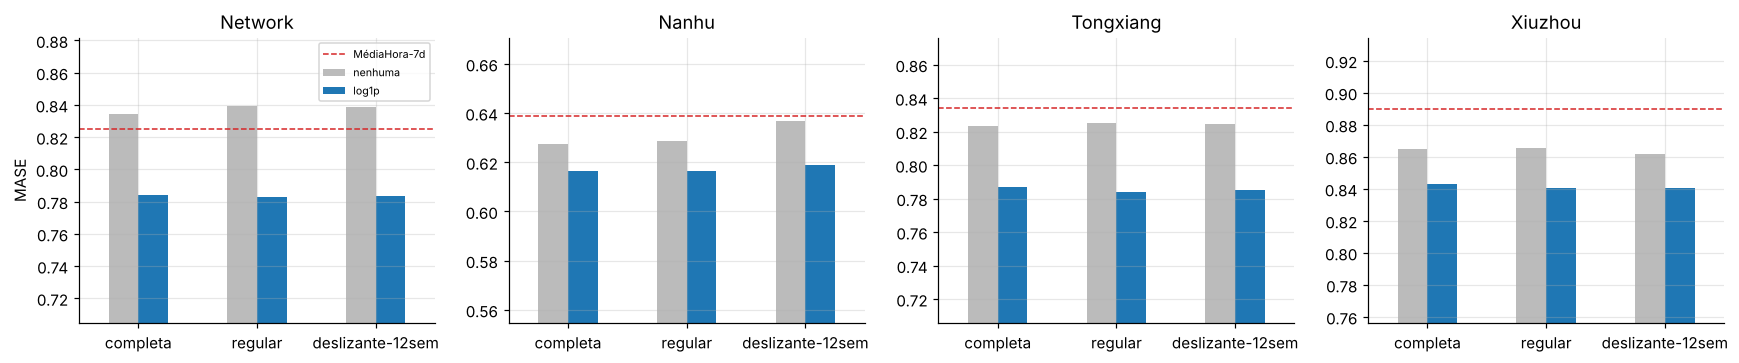

In [8]:
cfg = summarize(cfg_names, with_rule=False)
cfg[["modelo", "janela", "transformação"]] = cfg["model"].str.split(r" \| ", expand=True)
mase_cfg = cfg.pivot_table(index=["janela", "transformação"], columns="level", values="MASE")[LEVELS]
mase_cfg["média dos níveis"] = mase_cfg.mean(axis=1)
print("MASE médio nos 4 folds (menor é melhor)")
display(mase_cfg.sort_values("média dos níveis").round(3))

ft = fold_table(cfg_names).round(3)
print("MASE por fold (Rede)")
display(ft.loc["Network"])

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=False)
for a, lv in zip(ax, LEVELS):
    sub = cfg[cfg["level"] == lv]
    piv = sub.pivot(index="janela", columns="transformação", values="MASE").loc[list(WINDOW_START), ["nenhuma", "log1p"]]
    piv.plot.bar(ax=a, rot=0, color=["#BBBBBB", "#1F77B4"], legend=(lv == "Network"))
    ref = summarize(["MediaHora-7d"], [lv], with_rule=False)["MASE"].iloc[0]
    a.axhline(ref, color="#D62728", ls="--", lw=1, label="MédiaHora-7d")
    a.set(title=lv, xlabel="", ylabel="MASE" if lv == "Network" else "")
    a.set_ylim(min(piv.min().min(), ref) * 0.9, max(piv.max().max(), ref) * 1.05)
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Leitura.**

- **A transformação é a decisão que conta.** Com `log1p`, o MASE médio baixa em **todos os níveis e em todas as janelas** (na Rede, 0,783 contra 0,834 a 0,840), e o ganho repete-se em 46 dos 48 pares nível × janela × *fold*. As duas exceções são Nanhu no F4, com as janelas regular e deslizante, por diferenças mínimas (0,003 e 0,006). Sem transformação, o ETS nem sequer bate a MédiaHora-7d na Rede (linha tracejada no gráfico).
- **A janela quase não importa.** Com `log1p`, as três janelas ficam separadas por menos de 0,003 de MASE médio (0,756 a 0,758). Há uma razão simples: com $\alpha$ entre 0,02 e 0,06 por hora (secção 3.2), o nível "esquece" o passado em um a dois dias. O estado inicial no colapso de 2020 é rapidamente ultrapassado, e os parâmetros estimados com as três janelas são muito parecidos.
- **Escolhe-se a janela regular (desde 2020-04-01).** É a que tem o MASE médio mais baixo, embora por margem mínima, e é coerente com a Task 1: exclui o regime de COVID-19, que não se repete, e é o mesmo início usado na escala do MASE. A janela deslizante dá o mesmo resultado com muito menos dados, o que a torna menos robusta para modelos com mais parâmetros (ARIMA, SARIMAX).

**Implicação:** todas as secções seguintes modelam a série em **`log1p`**, com parâmetros estimados **desde 2020-04-01**.

### 2.3 Voltar à escala original: mediana ou média?

Ao calcular $e^{\hat z} - 1$ obtém-se a **mediana** prevista, que fica ligeiramente abaixo da **média** (porque a exponencial "estica" mais os valores altos do que os baixos). A correção habitual soma metade da variância dos resíduos antes de voltar à escala original: $\hat y = e^{\hat z + \sigma^2/2} - 1$.

Qual das duas convém depende da métrica: **a mediana minimiza o MAE** e **a média minimiza o RMSE**. Testa-se a correção na configuração escolhida, só como verificação.

In [9]:
regularINDOW, log1pRANSFORM = "regular", "log1p"
base_name = f"ETS(A,N,A) | {regularINDOW} | {log1pRANSFORM}"
run_model("ETS(A,N,A) | log1p + correção", lambda: ETSForecaster(window=regularINDOW, transform="log1p", bias_adj=True))
bias_tbl = summarize([base_name, "ETS(A,N,A) | log1p + correção"], with_rule=False)
bias_tbl["previsão"] = bias_tbl["model"].map({base_name: "mediana (sem correção)", "ETS(A,N,A) | log1p + correção": "média (com correção)"})
display(bias_tbl.pivot_table(index="level", columns="previsão", values=["MAE", "RMSE", "MASE"]).reindex(LEVELS).round(3))

p = RESULTS[base_name]["preds"]
bias_by_level = (p["y_pred"] - p["y_true"]).groupby(p["level"]).mean().reindex(LEVELS)
p2 = RESULTS["ETS(A,N,A) | log1p + correção"]["preds"]
display(pd.DataFrame({"viés médio sem correção (prev. − real)": bias_by_level,
                      "viés médio com correção": (p2["y_pred"] - p2["y_true"]).groupby(p2["level"]).mean().reindex(LEVELS)}).round(3))

ETS(A,N,A) | log1p + correção: 16 ajustes (nível × fold) em 6.3 s


MAE                                        MASE                                        RMSE                     
previsão  mediana (sem correção) média (com correção) mediana (sem correção) média (com correção) mediana (sem correção) média (com correção)
level                                                                                                                                        
Network                    5.476                5.617                  0.783                0.803                  7.622                7.744
Nanhu                      1.720                1.765                  0.616                0.632                  2.524                2.505
Tongxiang                  3.452                3.548                  0.784                0.806                  4.802                4.873
Xiuzhou                    3.247                3.371                  0.841                0.873                  4.611                4.638

,viés médio sem correção (prev. − real),viés médio com correção
level,,
Network,-0.760,0.775
Nanhu,-0.461,0.148
Tongxiang,-0.594,0.550
Xiuzhou,-0.841,0.467


**Leitura.**

- **Sem correção, a previsão fica um pouco abaixo do real:** em média −0,8 sessões/hora na Rede e −0,5 a −0,8 nos distritos. É o efeito esperado de prever a mediana.
- **A correção troca o sinal do viés** (passa a sobrestimar entre +0,1 e +0,8 sessões/hora) e **piora o MAE e o MASE em todos os níveis** (por exemplo, MASE na Rede de 0,783 para 0,803). Também não melhora o RMSE, exceto em Nanhu, por uma margem desprezável.

**Decisão:** mantém-se a **mediana** (sem correção), porque o MASE e o MAE são as métricas principais do protocolo. Fica registado que as previsões subestimam ligeiramente o volume total, o que importa se forem usadas para dimensionar capacidade.

In [10]:
TASK2_DECISIONS = {
    "window": regularINDOW,
    "window_start_rule": {"completa": "2020-01-01", "regular": "2020-04-01", "deslizante-12sem": "12 semanas antes do fim do treino"}[regularINDOW],
    "transform": log1pRANSFORM,
    "back_transform": "mediana: expm1 da previsão em log1p, sem correção de enviesamento",
    "parameters": "estimados uma vez por fold e nível; estado atualizado diariamente com os dados até T0, sem reestimar",
    "negative_forecasts": "cortadas a 0",
}
(OUT_DIR / "task2_decisions.json").write_text(json.dumps(TASK2_DECISIONS, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series(TASK2_DECISIONS).to_frame("decisão fixada para as secções seguintes"))

,decisão fixada para as secções seguintes
window,regular
window_start_rule,2020-04-01
transform,log1p
back_transform,"mediana: expm1 da previsão em log1p, sem corre..."
parameters,estimados uma vez por fold e nível; estado atu...
negative_forecasts,cortadas a 0


## 3. Suavização exponencial (ETS)

### 3.1 Ideia base

A suavização exponencial prevê com uma **média ponderada do passado em que os dados mais recentes pesam mais**, e os pesos caem de forma exponencial. O enquadramento **ETS (Error, Trend, Seasonal)** descreve cada modelo pelas suas componentes, cada uma atualizada a cada hora:

| Componente | O que representa | Parâmetro (0 a 1) |
|---|---|---|
| Nível $\ell_t$ | quantas sessões há "agora", em média | $\alpha$: rapidez com que o nível reage |
| Tendência $b_t$ | quanto o nível sobe ou desce por hora | $\beta$ |
| Sazonalidade $s_t$ | o desvio típico de cada hora do dia face ao nível | $\gamma$ |
| Amortecimento $\phi$ | trava a tendência à medida que o horizonte cresce | $\phi<1$ |

Para o modelo aditivo com tendência amortecida, ETS(A,Ad,A), a previsão para $h$ horas à frente é:

$$\hat y_{T+h|T} = \ell_T + (\phi + \phi^2 + \dots + \phi^h)\, b_T + s_{T+h-m(k+1)}$$

O ETS(A,N,A) é o mesmo sem tendência, e o ETS(A,A,A) é o Holt-Winters com tendência não amortecida ($\phi=1$). Como a série é modelada em `log1p`, a estrutura aditiva na escala logarítmica corresponde a uma estrutura **multiplicativa** na escala original (a sazonalidade cresce com o nível), sem os problemas dos modelos M com horas a zero.

**O que estes modelos captam e o que não captam:**

- **Captam** a dependência temporal (o nível acompanha a procura recente), a tendência (se existir) e **um** ciclo sazonal.
- **Não captam** um segundo ciclo (o semanal, de 168 h), os feriados, nem variáveis externas. As secções 3.3 e 6 tratam estes pontos.

Os parâmetros $\alpha, \beta, \gamma, \phi$ são estimados por máxima verosimilhança no treino de cada *fold*; os estados iniciais são obtidos por heurística (médias dos primeiros ciclos), o que torna o ajuste muito rápido.

### 3.2 Variantes com sazonalidade diária ($m=24$)

Comparam-se três estruturas de tendência, todas com a janela e a transformação fixadas na secção 2:

- **ETS(A,N,A)**: sem tendência (já avaliado na secção 2).
- **ETS(A,A,A)**: Holt-Winters aditivo, tendência linear.
- **ETS(A,Ad,A)**: tendência amortecida, mais prudente.

Dentro de cada *fold*, os modelos são ajustados aos mesmos dados, por isso o **AICc** (menor é melhor) também permite compará-los. O AICc mede o ajuste ao treino penalizando o número de parâmetros; a validação mede a previsão fora da amostra, que é o critério decisivo.

In [11]:
ETS_VARIANTS = {
    "ETS(A,N,A)": dict(trend=None, damped=False),
    "ETS(A,A,A)": dict(trend="add", damped=False),
    "ETS(A,Ad,A)": dict(trend="add", damped=True),
}
for nm, kw in ETS_VARIANTS.items():
    run_model(nm, lambda kw=kw: ETSForecaster(window=regularINDOW, transform=log1pRANSFORM, **kw))

# AICc no treino (mesmos dados dentro de cada fold e nível)
aicc = pd.concat([RESULTS[n]["info"].assign(model=n) for n in ETS_VARIANTS])
aicc_tbl = aicc.pivot_table(index=["level", "fold"], columns="model", values="AICc")[list(ETS_VARIANTS)]
aicc_tbl["menor AICc"] = aicc_tbl.idxmin(axis=1)
print("AICc no treino de cada fold (escala log1p; menor é melhor)")
display(aicc_tbl.reindex(LEVELS, level=0).round(0))

par_cols = ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]
par = aicc[["model", "level", "fold"] + [c for c in par_cols if c in aicc]].rename(
    columns={"smoothing_level": "α", "smoothing_trend": "β", "smoothing_seasonal": "γ", "damping_trend": "φ"})
print("Parâmetros estimados (média e intervalo entre folds)")
display(par.groupby(["model", "level"])[["α", "β", "γ", "φ"]].agg(["mean", "min", "max"]).reindex(LEVELS, level=1).round(3))

show_summary(list(ETS_VARIANTS), cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "Δ_MASE_vs_ref", "IC_inf", "IC_sup", "folds_ganhos", "melhor_que_ref"]);

ETS(A,N,A): 16 ajustes (nível × fold) em 6.5 s


ETS(A,A,A): 16 ajustes (nível × fold) em 10.3 s


ETS(A,Ad,A): 16 ajustes (nível × fold) em 15.6 s
AICc no treino de cada fold (escala log1p; menor é melhor)


model           ETS(A,N,A)  ETS(A,A,A)  ETS(A,Ad,A)  menor AICc
level     fold                                                 
Network   F1     2,530.000   2,561.000    2,534.000  ETS(A,N,A)
          F2     3,850.000   3,883.000    3,854.000  ETS(A,N,A)
          F3     5,880.000   5,920.000    5,884.000  ETS(A,N,A)
          F4     7,350.000   7,395.000    7,354.000  ETS(A,N,A)
Nanhu     F1     6,636.000   6,691.000    6,640.000  ETS(A,N,A)
          F2     9,791.000   9,848.000    9,795.000  ETS(A,N,A)
          F3    12,979.000  13,054.000   12,983.000  ETS(A,N,A)
          F4    16,093.000  16,183.000   16,097.000  ETS(A,N,A)
Tongxiang F1     4,320.000   4,335.000    4,323.000  ETS(A,N,A)
          F2     6,299.000   6,316.000    6,302.000  ETS(A,N,A)
          F3     8,616.000   8,637.000    8,620.000  ETS(A,N,A)
          F4    10,715.000  10,740.000   10,718.000  ETS(A,N,A)
Xiuzhou   F1     6,404.000   6,449.000    6,406.000  ETS(A,N,A)
          F2     9,769.000   9,824.000    9,771.000  ETS(A,N,A)
          F3    13,299.000  13,364.000   13,301.000  ETS(A,N,A)
          F4    16,394.000  16,461.000   16,397.000  ETS(A,N,A)

Parâmetros estimados (média e intervalo entre folds)


α                 β                 γ                 φ            
                       mean   min   max  mean   min   max  mean   min   max  mean   min   max
model       level                                                                            
ETS(A,A,A)  Network   0.066 0.065 0.068 0.000 0.000 0.000 0.078 0.066 0.093   NaN   NaN   NaN
            Nanhu     0.035 0.032 0.037 0.000 0.000 0.000 0.070 0.060 0.082   NaN   NaN   NaN
            Tongxiang 0.050 0.048 0.052 0.000 0.000 0.000 0.067 0.059 0.075   NaN   NaN   NaN
            Xiuzhou   0.039 0.037 0.041 0.000 0.000 0.000 0.065 0.053 0.084   NaN   NaN   NaN
ETS(A,Ad,A) Network   0.058 0.055 0.060 0.000 0.000 0.000 0.078 0.066 0.093 0.835 0.800 0.874
            Nanhu     0.018 0.011 0.023 0.000 0.000 0.000 0.070 0.061 0.083 0.800 0.800 0.800
            Tongxiang 0.046 0.044 0.048 0.000 0.000 0.000 0.067 0.059 0.075 0.951 0.880 0.975
            Xiuzhou   0.025 0.022 0.030 0.000 0.000 0.000 0.065 0.053 0.083 0.956 0.955 0.956
ETS(A,N,A)  Network   0.058 0.055 0.061   NaN   NaN   NaN 0.078 0.066 0.093   NaN   NaN   NaN
            Nanhu     0.017 0.010 0.023   NaN   NaN   NaN 0.070 0.061 0.083   NaN   NaN   NaN
            Tongxiang 0.046 0.044 0.048   NaN   NaN   NaN 0.067 0.059 0.075   NaN   NaN   NaN
            Xiuzhou   0.026 0.024 0.030   NaN   NaN   NaN 0.065 0.053 0.084   NaN   NaN   NaN

... (4 outputs left out)

--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,Ad,A)",3.452,4.803,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,A,A)",3.462,4.817,0.786,0.090,0.864,-0.048,-0.064,-0.035,4,sim


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,Ad,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.061,-0.038,4,sim
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4,sim
"ETS(A,A,A)",3.276,4.637,0.848,0.162,1.017,-0.042,-0.053,-0.030,4,sim


**Leitura.**

- **Não há tendência a captar à escala horária.** O $\beta$ estimado é praticamente zero em todos os níveis e *folds*. No ETS(A,Ad,A), o amortecimento $\phi$ fica no limite inferior permitido (0,80) em Nanhu e num *fold* da Rede, e com $\beta \approx 0$ o modelo "desliga" a tendência na prática. Por isso o ETS(A,Ad,A) dá praticamente os mesmos resultados do ETS(A,N,A), e o ETS(A,A,A), que é obrigado a projetar uma tendência linear, fica ligeiramente pior. O crescimento entre meses existe (Task 1), mas por hora é tão pequeno que o nível o acompanha sozinho.
- **O AICc escolhe o ETS(A,N,A) nos 16 casos** (4 níveis × 4 *folds*), o que coincide com a validação: o modelo mais simples é o melhor.
- **Parâmetros:** $\alpha$ vai de 0,017 (Nanhu) a 0,058 (Rede). Quanto mais ruidosa a série, mais o nível é suavizado: na Rede, o peso de uma hora cai para metade em cerca de 12 h; em Nanhu, em cerca de 40 h. O $\gamma$ (0,065 a 0,078) significa que o perfil horário se vai ajustando aos poucos, ao longo de semanas. Os parâmetros variam pouco entre *folds*, o que indica estabilidade.
- **O ETS(A,N,A) cumpre a regra de seleção nos quatro níveis:** MASE menor do que a MédiaHora-7d (Rede 0,783 contra 0,825, −5%; Nanhu 0,616 contra 0,639, −4%; Tongxiang 0,784 contra 0,834, −6%; Xiuzhou 0,841 contra 0,890, −5%), vitória nos 4 *folds* e IC 95% da diferença sempre abaixo de zero.

**Implicação:** fixa-se o **ETS(A,N,A)** como o melhor ETS de sazonalidade diária e como o modelo de referência estatístico que o ARIMA e o SARIMAX terão de superar.

### 3.3 Dupla sazonalidade: diária e semanal

A Task 1 encontrou dois ciclos: um diário forte (força 0,68 a 0,88) e um semanal fraco (cerca de 0,18). Um ETS com $m=24$ só representa o primeiro. Testam-se duas formas de incluir também o semanal:

1. **ETS(A,N,A) com $m=168$.** Um "dia" sazonal passa a ser uma semana: cada hora da semana (segunda às 10h, sábado às 15h, ...) tem o seu próprio fator. O ciclo diário fica incluído no semanal. **Custo:** cada fator só é atualizado uma vez por semana (em vez de uma vez por dia), por isso reage 7 vezes mais devagar e é mais ruidoso.
2. **MSTL + ETS.** A MSTL (decomposição em tendência, sazonalidade de 24 h, sazonalidade de 168 h e resto, por LOESS) separa os dois ciclos no treino. Retiram-se os ciclos, prevê-se o que sobra com um ETS(A,N,N) (só nível) e voltam a somar-se os ciclos, repetindo a última semana do treino:

$$\hat y_{T+h} = \underbrace{\hat\ell_{T}}_{\text{ETS do resto dessazonalizado}} + \underbrace{s^{(24)}_{T+h} + s^{(168)}_{T+h}}_{\text{semana sazonal projetada a partir do treino}}$$

Testam-se duas formas de projetar os ciclos: repetir **a última semana** do treino (como faz o `STLForecast` do `statsmodels`) ou repetir **a média das últimas 4 semanas**, que reduz o ruído de uma semana isolada. Em ambas, os ciclos ficam fixos durante cada *fold* (3 meses) e só o nível é atualizado diariamente. É uma limitação: se o perfil horário mudar dentro do trimestre, o modelo só o apanha no *fold* seguinte.

In [12]:
class MSTLETSForecaster(Forecaster):
    # MSTL (24 h e 168 h) no treino + ETS(A,N,N) no resto dessazonalizado; ciclos projetados com a última semana do treino.
    def __init__(self, window="regular", transform="log1p", periods=(24, 168), profile_weeks=1):
        self.window, self.transform, self.periods, self.profile_weeks = window, transform, periods, profile_weeks

    def _seasonal(self, n):
        # componente sazonal para as posições 0..n-1 da janela: treino = MSTL; depois = repetição da última semana
        if n <= self.n_tr:
            return self.seas_tr[:n]
        k = np.arange(n - self.n_tr)
        return np.concatenate([self.seas_tr, self.profile[k % len(self.profile)]])

    def fit(self, y_train):
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        z = fwd(y_train[self.s0:])
        from statsmodels.tsa.seasonal import MSTL  # importado aqui: evita uma importação circular nos processos paralelos
        dec = MSTL(z, periods=list(self.periods)).fit()
        self.seas_tr = np.asarray(dec.seasonal).sum(axis=1)
        self.n_tr = len(z)
        w = self.profile_weeks * 168
        self.profile = self.seas_tr[-w:].reshape(self.profile_weeks, 168).mean(axis=0)  # semana sazonal projetada
        self.res_ = ETSModel(z - self.seas_tr, error="add", trend=None, seasonal=None, initialization_method="heuristic").fit(disp=False)
        self.params = self.res_.params
        self.dec_ = dec
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        z = fwd(y_hist[self.s0:])
        n = len(z)
        seas = self._seasonal(n + 24)
        lvl = ETSModel(z - seas[:n], error="add", trend=None, seasonal=None, initialization_method="heuristic").smooth(self.params).forecast(24)
        return inv(lvl + seas[n:])

    def info(self):
        return {"smoothing_level": self.params[0], "AICc": self.res_.aicc}


run_model("ETS(A,N,A) m=168", lambda: ETSForecaster(m=168, window=regularINDOW, transform=log1pRANSFORM))
MSTL1, MSTL4 = "MSTL + ETS (1 sem)", "MSTL + ETS (4 sem)"
run_model(MSTL1, lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=1))
run_model(MSTL4, lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=4))

SEASONAL_SET = ["ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL1, MSTL4]
show_summary(SEASONAL_SET, cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "Δ_MASE_vs_ref", "IC_inf", "IC_sup", "folds_ganhos", "melhor_que_ref"]);

ETS(A,N,A) m=168: 16 ajustes (nível × fold) em 22.2 s


MSTL + ETS (1 sem): 16 ajustes (nível × fold) em 15.5 s


MSTL + ETS (4 sem): 16 ajustes (nível × fold) em 15.8 s
--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,-0.042,-0.060,-0.027,4,sim
"ETS(A,N,A) m=168",5.631,7.822,0.805,0.109,0.944,-0.020,-0.040,-0.005,3,sim
MSTL + ETS (4 sem),5.925,8.237,0.847,0.110,0.981,0.022,0.001,0.039,1,não
MSTL + ETS (1 sem),6.491,9.010,0.929,0.141,1.103,0.103,0.078,0.125,0,não


--- Nanhu ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",1.720,2.524,0.616,0.124,0.764,-0.022,-0.031,-0.015,4,sim
"ETS(A,N,A) m=168",1.780,2.605,0.639,0.147,0.826,0.000,-0.017,0.015,3,não
MSTL + ETS (4 sem),1.934,2.807,0.696,0.171,0.924,0.057,0.030,0.078,0,não
MSTL + ETS (1 sem),2.097,3.028,0.754,0.188,1.005,0.116,0.086,0.139,0,não


--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,N,A) m=168",3.523,4.895,0.800,0.094,0.882,-0.034,-0.052,-0.021,4,sim
MSTL + ETS (4 sem),3.783,5.249,0.860,0.098,0.953,0.025,0.005,0.042,0,não
MSTL + ETS (1 sem),4.140,5.729,0.940,0.116,1.079,0.106,0.082,0.126,0,não


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4,sim
"ETS(A,N,A) m=168",3.308,4.687,0.856,0.165,1.031,-0.033,-0.047,-0.021,4,sim
MSTL + ETS (4 sem),3.520,4.966,0.911,0.180,1.094,0.022,0.005,0.038,0,não
MSTL + ETS (1 sem),3.910,5.491,1.012,0.210,1.247,0.122,0.100,0.141,0,não


**Leitura.**

- **Juntar o ciclo semanal não ajuda; piora.** O ETS(A,N,A) com $m=24$ continua o melhor em todos os níveis.
- **ETS com $m=168$:** bate a referência na Rede, em Tongxiang e em Xiuzhou, mas fica sempre atrás do ETS de 24 h e não bate a referência em Nanhu (IC inclui zero). Cada fator semanal só é atualizado uma vez por semana, por isso o perfil reage 7 vezes mais devagar e com mais ruído, e o ganho de representar um ciclo semanal fraco (força ≈ 0,18) não compensa.
- **MSTL + ETS:** é o pior dos modelos estatísticos. Ao repetir a última semana, fica pior do que a referência em todos os níveis (MASE 0,93 na Rede), porque uma única semana traz o seu próprio ruído para os 3 meses seguintes. A média de 4 semanas corrige grande parte do problema (0,85), mas continua sem bater a MédiaHora-7d em nenhum nível. Os resíduos da secção 3.5 mostram a causa: no treino, a MSTL ajusta-se demasiado (autocorrelação de −0,25 a 24 h, ou seja, absorve ruído como se fosse sazonalidade) e depois os ciclos ficam fixos durante todo o *fold*, sem acompanhar mudanças no perfil.

**Implicação:** com estes dados, o ciclo semanal é demasiado fraco para justificar a complexidade extra. A sazonalidade diária, atualizada continuamente ($\gamma$), é o que dá o ganho. Os feriados, que alteram o nível de dias inteiros, ficam por modelar e são tratados com variáveis exógenas na secção 6.

### 3.4 Comparação com as *baselines*

Juntam-se os modelos ETS às *baselines* da Task 1. A tabela aplica a regra de seleção do protocolo face à MédiaHora-7d: o modelo tem de ter MASE médio menor, ganhar em pelo menos 3 dos 4 *folds* e ter o IC 95% da diferença pareada de MASE diário totalmente abaixo de zero.

In [13]:
ETS_ALL = list(ETS_VARIANTS) + ["ETS(A,N,A) m=168", MSTL1, MSTL4]
COMPARE = ["SNaive-24", "MediaHora-7d"] + ETS_ALL
cmp_tbl = show_summary(COMPARE, cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "folds_ganhos", "IC_inf", "IC_sup", "melhor_que_ref", "pico_acerto", "pico_MAE", "ajuste_s", "ms_origem"])

print("MASE por fold")
display(fold_table(COMPARE).round(3))

--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,4.000,-0.060,-0.027,sim,0.526,9.865,0.026,7.947
"ETS(A,Ad,A)",5.476,7.622,0.783,0.096,0.890,4.000,-0.060,-0.027,sim,0.526,9.865,0.053,19.576
"ETS(A,A,A)",5.518,7.689,0.789,0.094,0.894,4.000,-0.054,-0.021,sim,0.526,9.881,0.065,12.758
"ETS(A,N,A) m=168",5.631,7.822,0.805,0.109,0.944,3.000,-0.040,-0.005,sim,0.507,9.297,0.082,27.677
MediaHora-7d,5.772,7.965,0.825,0.103,0.933,NaN,NaN,NaN,NaN,0.501,8.689,0.000,0.020
MSTL + ETS (4 sem),5.925,8.237,0.847,0.110,0.981,1.000,0.001,0.039,não,0.460,8.389,1.608,2.343
MSTL + ETS (1 sem),6.491,9.010,0.929,0.141,1.103,0.000,0.078,0.125,não,0.444,8.529,1.525,2.202
SNaive-24,7.143,9.826,1.022,0.139,1.187,0.000,0.174,0.219,não,0.406,8.039,0.000,0.009


--- Nanhu ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,Ad,A)",1.720,2.523,0.616,0.124,0.764,4.000,-0.031,-0.015,sim,0.438,4.291,0.072,19.229
"ETS(A,N,A)",1.720,2.524,0.616,0.124,0.764,4.000,-0.031,-0.015,sim,0.438,4.292,0.023,8.038
"ETS(A,A,A)",1.729,2.531,0.620,0.122,0.765,4.000,-0.028,-0.012,sim,0.438,4.250,0.043,12.620
MediaHora-7d,1.784,2.556,0.639,0.115,0.769,NaN,NaN,NaN,NaN,0.446,3.245,0.000,0.032
"ETS(A,N,A) m=168",1.780,2.605,0.639,0.147,0.826,3.000,-0.017,0.015,não,0.452,3.974,0.072,27.122
MSTL + ETS (4 sem),1.934,2.807,0.696,0.171,0.924,0.000,0.030,0.078,não,0.413,3.180,1.655,2.392
MSTL + ETS (1 sem),2.097,3.028,0.754,0.188,1.005,0.000,0.086,0.139,não,0.416,2.851,1.664,2.287
SNaive-24,2.273,3.316,0.814,0.144,0.979,0.000,0.159,0.194,não,0.315,3.117,0.000,0.008


--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,4.000,-0.066,-0.037,sim,0.477,6.585,0.022,8.099
"ETS(A,Ad,A)",3.452,4.803,0.784,0.091,0.861,4.000,-0.066,-0.037,sim,0.477,6.585,0.074,19.635
"ETS(A,A,A)",3.462,4.817,0.786,0.090,0.864,4.000,-0.064,-0.035,sim,0.477,6.578,0.049,12.539
"ETS(A,N,A) m=168",3.523,4.895,0.800,0.094,0.882,4.000,-0.052,-0.021,sim,0.491,6.461,0.068,27.208
MediaHora-7d,3.672,5.055,0.834,0.105,0.922,NaN,NaN,NaN,NaN,0.422,5.564,0.000,0.015
MSTL + ETS (4 sem),3.783,5.249,0.860,0.098,0.953,0.000,0.005,0.042,não,0.420,5.554,1.560,2.336
MSTL + ETS (1 sem),4.140,5.729,0.940,0.116,1.079,0.000,0.082,0.126,não,0.337,5.437,1.689,2.444
SNaive-24,4.541,6.308,1.032,0.125,1.159,0.000,0.175,0.220,não,0.367,4.828,0.000,0.007


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,Ad,A)",3.247,4.611,0.841,0.161,1.012,4.000,-0.061,-0.038,sim,0.392,7.696,0.062,18.872
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,4.000,-0.060,-0.038,sim,0.392,7.694,0.026,8.128
"ETS(A,A,A)",3.276,4.637,0.848,0.162,1.017,4.000,-0.053,-0.030,sim,0.389,7.589,0.042,12.827
"ETS(A,N,A) m=168",3.308,4.687,0.856,0.165,1.031,4.000,-0.047,-0.021,sim,0.427,7.303,0.084,28.288
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,0.383,6.124,0.000,0.012
MSTL + ETS (4 sem),3.520,4.966,0.911,0.180,1.094,0.000,0.005,0.038,não,0.419,6.313,1.701,2.193
MSTL + ETS (1 sem),3.910,5.491,1.012,0.210,1.247,0.000,0.100,0.141,não,0.296,5.841,1.583,2.169
SNaive-24,4.365,6.064,1.130,0.204,1.342,0.000,0.221,0.262,não,0.307,4.877,0.000,0.008


MASE por fold


fold                            F1    F2    F3    F4
level     model                                     
Network   ETS(A,A,A)         0.804 0.665 0.794 0.894
          ETS(A,Ad,A)        0.798 0.656 0.789 0.890
          ETS(A,N,A)         0.798 0.656 0.789 0.890
          ETS(A,N,A) m=168   0.805 0.679 0.792 0.944
          MSTL + ETS (1 sem) 0.906 0.759 0.946 1.103
          MSTL + ETS (4 sem) 0.836 0.713 0.861 0.981
          MediaHora-7d       0.847 0.685 0.836 0.933
          SNaive-24          1.018 0.846 1.036 1.187
Nanhu     ETS(A,A,A)         0.675 0.501 0.537 0.765
          ETS(A,Ad,A)        0.671 0.495 0.536 0.764
          ETS(A,N,A)         0.671 0.495 0.536 0.764
          ETS(A,N,A) m=168   0.684 0.504 0.541 0.826
          MSTL + ETS (1 sem) 0.789 0.591 0.630 1.005
          MSTL + ETS (4 sem) 0.723 0.538 0.597 0.924
          MediaHora-7d       0.699 0.527 0.560 0.769
          SNaive-24          0.887 0.677 0.711 0.979
Tongxiang ETS(A,A,A)         0.864 0.673 0.755 0.854
          ETS(A,Ad,A)        0.861 0.669 0.754 0.854
          ETS(A,N,A)         0.861 0.669 0.754 0.854
          ETS(A,N,A) m=168   0.874 0.690 0.756 0.882
          MSTL + ETS (1 sem) 0.982 0.808 0.893 1.079
          MSTL + ETS (4 sem) 0.925 0.739 0.821 0.953
          MediaHora-7d       0.922 0.701 0.800 0.915
          SNaive-24          1.104 0.878 0.986 1.159
Xiuzhou   ETS(A,A,A)         0.762 0.667 0.947 1.017
          ETS(A,Ad,A)        0.758 0.659 0.934 1.012
          ETS(A,N,A)         0.758 0.659 0.934 1.012
          ETS(A,N,A) m=168   0.765 0.676 0.954 1.031
          MSTL + ETS (1 sem) 0.915 0.773 1.112 1.247
          MSTL + ETS (4 sem) 0.808 0.713 1.030 1.094
          MediaHora-7d       0.807 0.707 0.988 1.058
          SNaive-24          1.013 0.906 1.260 1.342

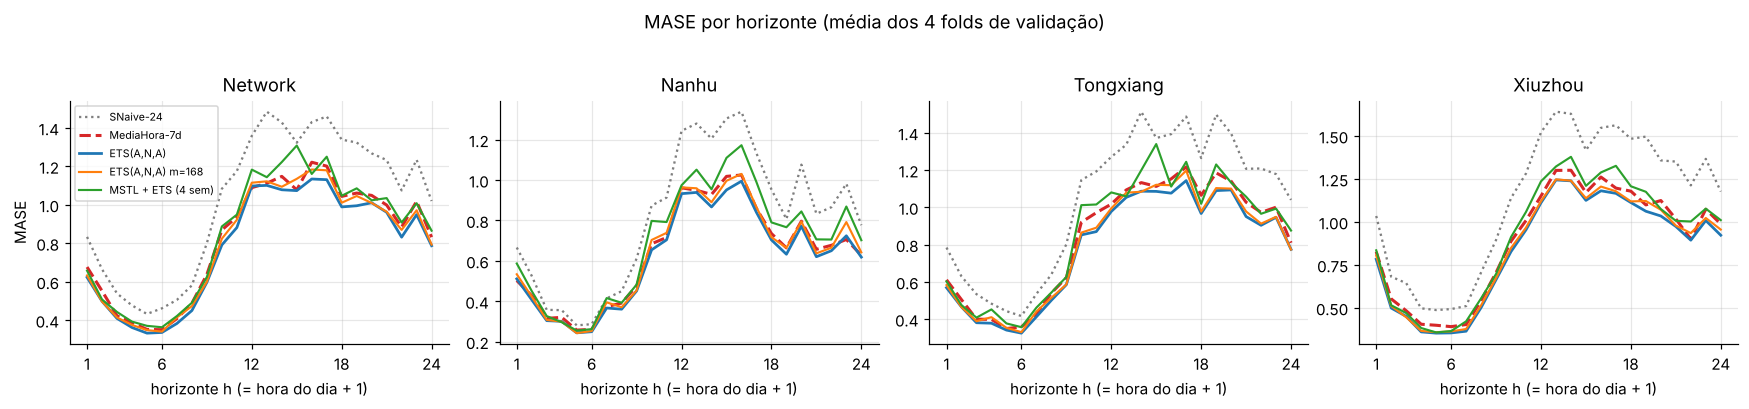

Δ MASE h=1-6  Δ MASE h=7-24  horizontes em que ganha
modelo             nível                                                          
ETS(A,N,A)         Network          -0.030         -0.046                       23
                   Nanhu            -0.011         -0.026                       22
                   Tongxiang        -0.027         -0.058                       24
                   Xiuzhou          -0.043         -0.051                       24
ETS(A,N,A) m=168   Network          -0.022         -0.019                       20
                   Nanhu            -0.004          0.002                       13
                   Tongxiang        -0.015         -0.040                       20
                   Xiuzhou          -0.035         -0.033                       22
MSTL + ETS (4 sem) Network          -0.001          0.030                        6
                   Nanhu             0.016          0.071                        2
                   Tongxiang         0.008          0.031                        9
                   Xiuzhou          -0.022          0.036                        8

In [14]:
STYLES = {"MediaHora-7d": dict(color="#D62728", ls="--", lw=2), "SNaive-24": dict(color="#7F7F7F", ls=":", lw=1.5),
          "ETS(A,N,A)": dict(color="#1F77B4", lw=1.8), "ETS(A,N,A) m=168": dict(color="#FF7F0E", lw=1.4), MSTL4: dict(color="#2CA02C", lw=1.4)}
plot_by_horizon(["SNaive-24", "MediaHora-7d", "ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL4], styles=STYLES,
                title="MASE por horizonte (média dos 4 folds de validação)")

# Diferença face à referência por horizonte: horizontes iniciais (manhã cedo) vs restantes
rows = []
for n in ["ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL4]:
    for lv in LEVELS:
        a = RESULTS[n]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        b = RESULTS["MediaHora-7d"]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        d = (a - b)
        rows.append({"modelo": n, "nível": lv, "Δ MASE h=1-6": d.loc[1:6].mean(), "Δ MASE h=7-24": d.loc[7:24].mean(),
                     "horizontes em que ganha": int((d < 0).sum())})
display(pd.DataFrame(rows).set_index(["modelo", "nível"]).round(3))

**Leitura.**

- **Ganho em quase todas as horas.** O ETS(A,N,A) fica abaixo da referência em 22 a 24 dos 24 horizontes, em todos os níveis. O ganho é maior durante o dia ($h$ = 7 a 24: −0,03 a −0,06 de MASE) do que de madrugada ($h$ = 1 a 6). Como a emissão é à meia-noite, o ganho não vem de "estar mais perto" do último dado. Vem de um perfil horário mais estável do que a média simples de 7 dias e de um nível que acompanha a procura mais recente.
- **Estabilidade.** O ETS(A,N,A) ganha à referência nos 4 *folds* de todos os níveis. O pior *fold* é o F4 (verão de 2021) na Rede, em Nanhu e em Xiuzhou. Em Xiuzhou o F4 chega a um MASE de 1,01, ainda assim abaixo da referência (1,06). Em Tongxiang o pior é o F1. O F2 (2021-Q1) é o mais fácil em todos os níveis, como já acontecia com as *baselines* na Task 1.
- **O ponto fraco são os picos.** O ETS acerta um pouco mais na **hora** de pico (53% contra 50% na Rede), mas falha mais no **valor** do pico (9,9 contra 8,7 sessões na Rede; 4,3 contra 3,2 em Nanhu). A suavização e a previsão da mediana em `log1p` achatam os máximos, o que se vê também no exemplo abaixo.
- **Custo:** desprezável. O ajuste leva cerca de 0,03 s por *fold* e a previsão de um dia cerca de 8 ms. As *baselines* são ainda mais rápidas, mas nenhum dos custos pesa na decisão.

MediaHora-7d  ETS(A,N,A)  MSTL + ETS (4 sem)
level     tipo                                                    
Network   dia normal         0.820       0.776               0.836
          feriado            0.892       0.867               0.970
Nanhu     dia normal         0.638       0.615               0.693
          feriado            0.651       0.644               0.731
Tongxiang dia normal         0.832       0.780               0.854
          feriado            0.866       0.833               0.925
Xiuzhou   dia normal         0.886       0.837               0.905
          feriado            0.936       0.886               0.985

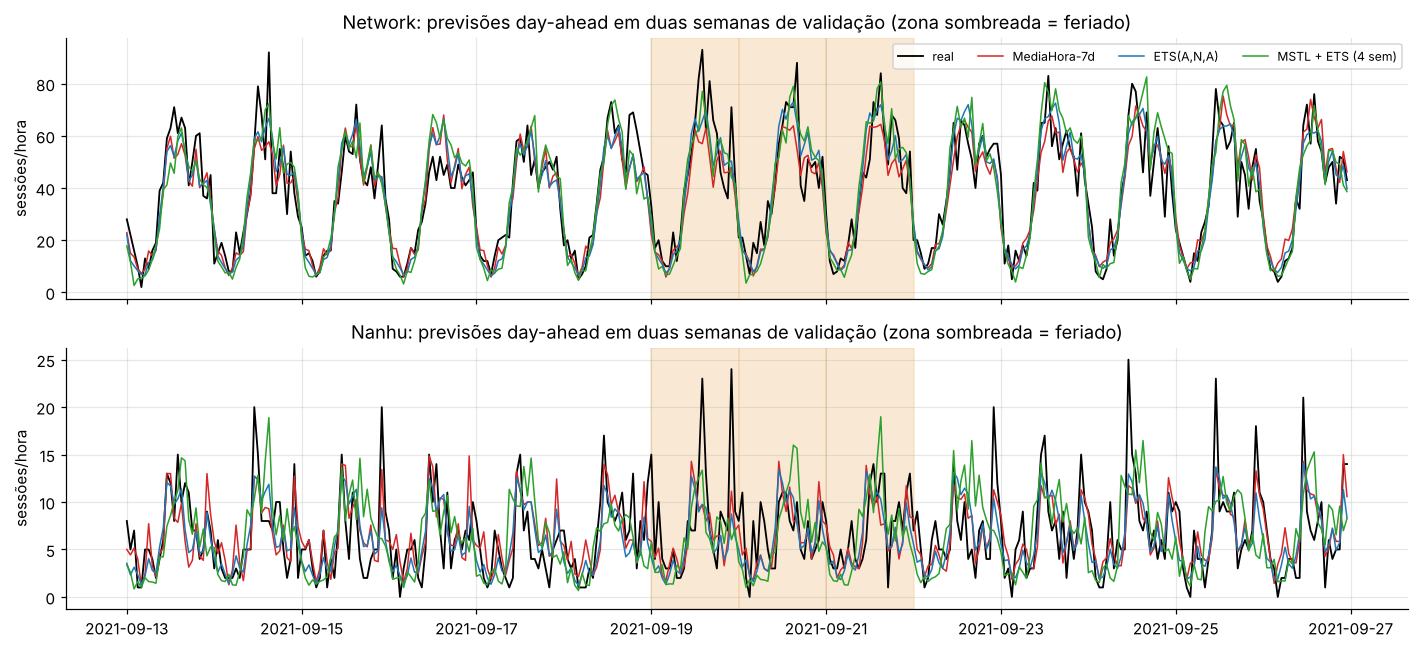

In [15]:
# Desempenho por tipo de dia (feriado vs normal) e um exemplo de previsões
rows = []
for n in ["MediaHora-7d", "ETS(A,N,A)", MSTL4]:
    rd = RESULTS[n]["res_d"]
    rd = rd.assign(tipo=np.where(rd["day"].isin(HOLIDAY_DAYS), "feriado", "dia normal"))
    rows.append(rd.groupby(["level", "tipo"])["MASE_dia"].mean().rename(n))
display(pd.concat(rows, axis=1).reindex(LEVELS, level=0).round(3))

ex_from, ex_to = pd.Timestamp("2021-09-13"), pd.Timestamp("2021-09-26 23:00")
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, lv in zip(axes, ["Network", "Nanhu"]):
    ax.plot(series.loc[ex_from:ex_to, lv], color="black", lw=1.2, label="real")
    for n, c in [("MediaHora-7d", "#D62728"), ("ETS(A,N,A)", "#1F77B4"), (MSTL4, "#2CA02C")]:
        pr = RESULTS[n]["preds"].query("level == @lv").set_index("timestamp")["y_pred"].loc[ex_from:ex_to]
        ax.plot(pr, color=c, lw=1, label=n)
    for d in pd.date_range(ex_from, ex_to, freq="D"):
        if d in HOLIDAY_DAYS:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="#F2C894", alpha=0.4)
    ax.set(title=f"{lv}: previsões day-ahead em duas semanas de validação (zona sombreada = feriado)", ylabel="sessões/hora")
axes[0].legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

**Leitura.**

- **Ganho em quase todas as horas.** O ETS(A,N,A) fica abaixo da referência em 22 a 24 dos 24 horizontes, em todos os níveis. O ganho é maior durante o dia ($h$ = 7 a 24: −0,03 a −0,06 de MASE) do que de madrugada ($h$ = 1 a 6). Como a emissão é à meia-noite, o ganho não vem de "estar mais perto" do último dado. Vem de um perfil horário mais estável do que a média simples de 7 dias e de um nível que acompanha a procura mais recente.
- **Estabilidade.** O ETS(A,N,A) ganha à referência nos 4 *folds* de todos os níveis. O pior *fold* é o F4 (verão de 2021) na Rede, em Nanhu e em Xiuzhou. Em Xiuzhou o F4 chega a um MASE de 1,01, ainda assim abaixo da referência (1,06). Em Tongxiang o pior é o F1. O F2 (2021-Q1) é o mais fácil em todos os níveis, como já acontecia com as *baselines* na Task 1.
- **O ponto fraco são os picos.** O ETS acerta um pouco mais na **hora** de pico (53% contra 50% na Rede), mas falha mais no **valor** do pico (9,9 contra 8,7 sessões na Rede; 4,3 contra 3,2 em Nanhu). A suavização e a previsão da mediana em `log1p` achatam os máximos, o que se vê também no exemplo abaixo.
- **Custo:** desprezável. O ajuste leva cerca de 0,03 s por *fold* e a previsão de um dia cerca de 8 ms. As *baselines* são ainda mais rápidas, mas nenhum dos custos pesa na decisão.b

### 3.5 Diagnóstico dos resíduos

Se um modelo aproveitou toda a informação da série, os resíduos (real − ajustado, no treino) devem parecer **ruído branco**: sem autocorrelação, com média zero e variância constante. Verifica-se para o melhor ETS de 24 h e para a MSTL + ETS (os resíduos de treino são os mesmos nas duas variantes de projeção), no treino do último *fold* (F4, o mais longo), na escala `log1p` em que os modelos são estimados:

- **ACF dos resíduos** até 336 h: barras fora da banda de ±1,96/√n indicam padrão por captar (em especial em 24, 168 e 336 h).
- **Teste de Ljung-Box** nos *lags* 24, 48 e 168: hipótese nula = sem autocorrelação até esse *lag*; p-valor < 0,05 indica padrão restante. Com milhares de observações, o teste rejeita quase sempre, por isso olha-se também para o **tamanho** das autocorrelações.
- **QQ-plot**: compara os resíduos com uma normal. A normalidade não é exigida para prever, mas caudas pesadas indicam erros extremos (feriados, quebras).
- **Resíduos por hora do dia**: o modelo erra mais a certas horas?

In [16]:
F4 = FOLD_BY_NAME["F4"]
n_train_f4 = day_idx(F4["val"][0]) * 24

def fit_on_f4(make_model, level):
    m = make_model()
    m.fit(Y[level][:n_train_f4].copy())
    return m

DIAG_MODELS = {
    "ETS(A,N,A)": lambda: ETSForecaster(window=regularINDOW, transform=log1pRANSFORM, **ETS_VARIANTS["ETS(A,N,A)"]),
    MSTL4: lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=4),
}
RESID = {(n, lv): np.asarray(fit_on_f4(mk, lv).res_.resid) for n, mk in DIAG_MODELS.items() for lv in LEVELS}

lb_rows = []
for (n, lv), r in RESID.items():
    lb = acorr_ljungbox(r, lags=[24, 48, 168])
    a = acf(r, nlags=336, fft=True)
    lb_rows.append({"modelo": n, "nível": lv, "média": r.mean(), "dp": r.std(),
                    "ACF lag 1": a[1], "ACF lag 24": a[24], "ACF lag 168": a[168], "ACF lag 336": a[336],
                    "máx |ACF| (1-336)": np.abs(a[1:]).max(),
                    "LB p (24)": lb["lb_pvalue"].iloc[0], "LB p (48)": lb["lb_pvalue"].iloc[1], "LB p (168)": lb["lb_pvalue"].iloc[2]})
display(pd.DataFrame(lb_rows).set_index(["modelo", "nível"]).round(3))

média    dp  ACF lag 1  ACF lag 24  ACF lag 168  ACF lag 336  máx |ACF| (1-336)  LB p (24)  LB p (48)  LB p (168)
modelo             nível                                                                                                                       
ETS(A,N,A)         Network    0.001 0.338      0.078       0.008        0.019        0.013              0.078      0.000      0.000       0.000
                   Nanhu     -0.001 0.505      0.073       0.013        0.035        0.018              0.073      0.000      0.000       0.000
                   Tongxiang  0.002 0.395      0.054       0.020        0.014        0.018              0.054      0.000      0.000       0.000
                   Xiuzhou    0.002 0.512      0.103      -0.001        0.006        0.009              0.103      0.000      0.000       0.000
MSTL + ETS (4 sem) Network    0.001 0.266      0.038      -0.255       -0.161       -0.172              0.255      0.000      0.000       0.000
                   Nanhu     -0.000 0.396      0.035      -0.262       -0.155       -0.167              0.262      0.000      0.000       0.000
                   Tongxiang  0.001 0.311      0.033      -0.236       -0.175       -0.158              0.236      0.000      0.000       0.000
                   Xiuzhou    0.002 0.408      0.076      -0.263       -0.166       -0.155              0.263      0.000      0.000       0.000

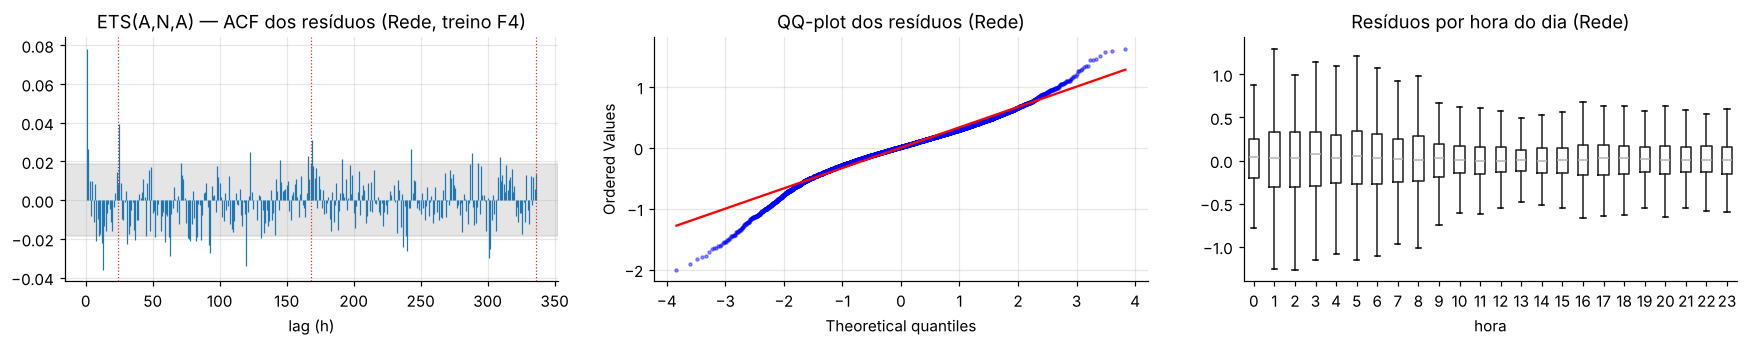

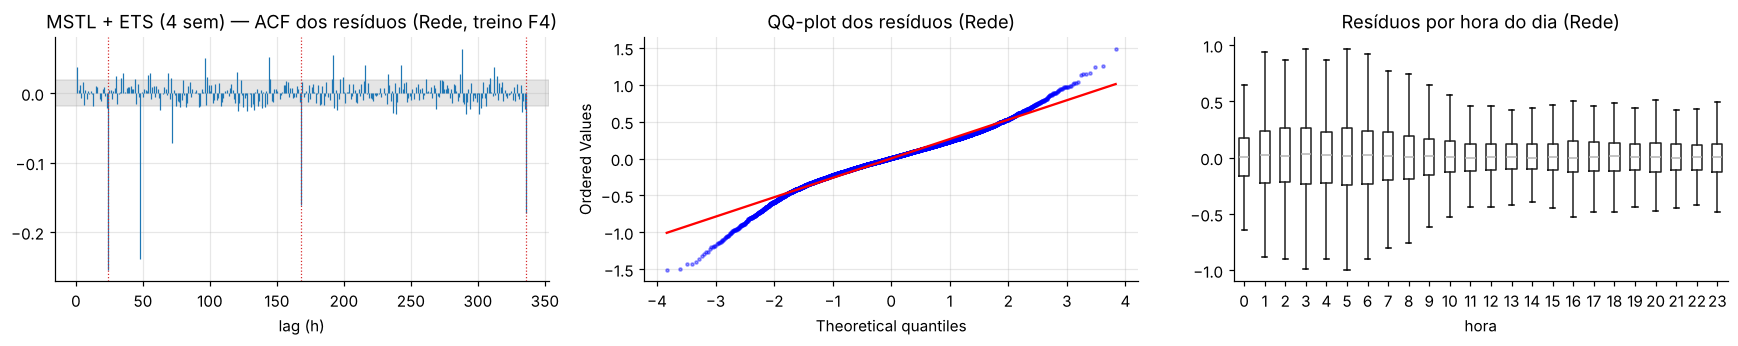

In [17]:
for n in DIAG_MODELS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
    r = RESID[(n, "Network")]
    a = acf(r, nlags=336, fft=True)
    band = 1.96 / np.sqrt(len(r))
    axes[0].vlines(range(1, 337), 0, a[1:], color="#1F77B4", lw=0.8)
    axes[0].axhspan(-band, band, color="#AAAAAA", alpha=0.3)
    for k in (24, 168, 336):
        axes[0].axvline(k, color="#D62728", ls=":", lw=0.8)
    axes[0].set(title=f"{n} — ACF dos resíduos (Rede, treino F4)", xlabel="lag (h)")
    stats.probplot(r, dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set(markersize=2, alpha=0.4)
    axes[1].set_title("QQ-plot dos resíduos (Rede)")
    hrs = series.index[n_train_f4 - len(r):n_train_f4].hour
    pd.DataFrame({"hora": hrs, "resíduo": r}).boxplot(column="resíduo", by="hora", ax=axes[2], showfliers=False, grid=False)
    axes[2].set(title="Resíduos por hora do dia (Rede)", xlabel="hora", ylabel="")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

**Leitura.**

- **ETS(A,N,A): os resíduos estão perto de ruído branco.** A média é praticamente zero e as autocorrelações são pequenas (no máximo 0,05 a 0,10, sempre no *lag* 1; nos *lags* 24, 168 e 336 ficam abaixo de 0,04). O Ljung-Box rejeita a hipótese de ruído branco em todos os níveis (p < 0,001), mas, com mais de 10 000 observações, o teste deteta autocorrelações muito pequenas para terem efeito prático. O pequeno pico no *lag* 1 é dependência de curto prazo que um ARIMA pode captar (secções 4 e 5). Os pequenos picos em 168 e 336 h são o ciclo semanal fraco, que já se viu não compensar modelar.
- **MSTL + ETS: sobreajuste.** Os resíduos têm menor variância no treino (0,27 contra 0,34 na Rede), mas autocorrelação **negativa** forte nos *lags* 24 (≈ −0,25), 168 e 336 (≈ −0,16). A decomposição tirou "sazonalidade" a mais, incluindo ruído. Ajusta melhor o passado e prevê pior o futuro, o que explica os resultados da secção 3.3.
- **QQ-plot:** a cauda esquerda é mais pesada do que a de uma normal, devido a quedas bruscas (horas noturnas com 0 ou 1 sessões, que em `log1p` são grandes desvios). A normalidade não é necessária para a previsão pontual, mas indica que intervalos de previsão baseados na normal seriam pouco fiáveis nas caudas.
- **Resíduos por hora:** são maiores de madrugada (0h–8h). É o mesmo efeito do `log1p` com contagens baixas visto na secção 2.1. Em sessões, os erros maiores continuam a ser os do dia, como mostra o gráfico de MASE por horizonte.

### 3.6 Exportação para as secções seguintes

As previsões de validação de cada modelo ficam em `task2_outputs/` no formato comum (`model, level, fold, origin, timestamp, h, y_true, y_pred`), com os tempos de ajuste e de previsão em `fit_times_task2.csv`. A secção 7 (comparação global) junta estes ficheiros com os dos modelos ARIMA e SARIMAX.

In [18]:
EXPORT = list(BASELINES) + ETS_ALL
slug = lambda s: s.lower().replace("(", "").replace(")", "").replace(",", "").replace(" + ", "_").replace(" ", "_").replace("=", "")
for n in EXPORT:
    RESULTS[n]["preds"].to_csv(OUT_DIR / f"preds_task2_{slug(n)}.csv", index=False)
fit_times = pd.concat([RESULTS[n]["res_f"][["model", "level", "fold", "fit_s", "ms_per_origin"]] for n in EXPORT], ignore_index=True)
fit_times.to_csv(OUT_DIR / "fit_times_task2.csv", index=False)
summarize(EXPORT).to_csv(OUT_DIR / "summary_ets_task2.csv", index=False)
print(f"{len(EXPORT)} ficheiros de previsões + fit_times_task2.csv + summary_ets_task2.csv em {OUT_DIR.resolve()}")

11 ficheiros de previsões + fit_times_task2.csv + summary_ets_task2.csv em /home/claude/p2/task2_outputs


### 3.7 Conclusões das secções 1 a 3

**Base comum (para as secções seguintes)**

- O motor de avaliação reproduz exatamente as *baselines* da Task 1 e garante por construção que nenhum modelo vê dados do dia previsto nem do teste.
- Decisões fixadas: série modelada em **`log1p`**, parâmetros estimados **desde 2020-04-01**, previsão devolvida como **mediana** (`expm1`, sem correção) e cortada a zero (ficheiro `task2_decisions.json`).

**Suavização exponencial**

| Modelo | Rede | Nanhu | Tongxiang | Xiuzhou | Bate a referência? |
|---|---|---|---|---|---|
| MédiaHora-7d (referência) | 0,825 | 0,639 | 0,834 | 0,890 | — |
| **ETS(A,N,A)**, $m=24$ | **0,783** | **0,616** | **0,784** | **0,841** | sim, nos 4 níveis |
| ETS(A,Ad,A) | 0,783 | 0,616 | 0,784 | 0,841 | sim (igual ao anterior: a tendência é anulada) |
| ETS(A,A,A) | 0,789 | 0,620 | 0,786 | 0,848 | sim, mas pior do que sem tendência |
| ETS(A,N,A), $m=168$ | 0,805 | 0,639 | 0,800 | 0,856 | em 3 níveis (não em Nanhu) |
| MSTL + ETS (4 sem) | 0,847 | 0,696 | 0,860 | 0,911 | não |

*(MASE médio nos 4 folds de validação.)*

- **Melhor modelo ETS: ETS(A,N,A) em `log1p`.** Reduz o MASE entre 3,5% e 6% face à MédiaHora-7d em todos os níveis, ganha nos 4 *folds* e em quase todos os horizontes, e custa milissegundos.
- **Pontos fortes:** simples, estável entre *folds* (parâmetros quase iguais), interpretável (nível + perfil horário que se vão atualizando) e muito rápido.
- **Limitações:** só representa um ciclo sazonal; não sabe de feriados (erra mais nesses dias); achata os picos (erro do valor do pico maior do que o da referência); subestima ligeiramente o volume (previsão da mediana); resta uma pequena autocorrelação de curto prazo nos resíduos.
- **O que não funcionou:** a tendência (inexistente à escala horária) e as tentativas de incluir o ciclo semanal ($m=168$ e MSTL). O ciclo semanal é fraco, e representá-lo custa mais em ruído do que ganha em sinal.

**Para as secções seguintes:** o **ETS(A,N,A)** passa a ser a fasquia dos modelos estatísticos. O ARIMA (secções 4–5) pode ganhar na dependência de curto prazo que resta nos resíduos, e o SARIMAX (secção 6) nos feriados e nos picos, que o ETS não modela.